# 📦 DEMO: TỐI ƯU HÓA TỒN KHO ĐA KỲ BẰNG REINFORCEMENT LEARNING (RL)

## 📌 MỤC LỤC BÀI THUYẾT TRÌNH
1. **Phần 1:** Giới thiệu bài toán & Mô hình hóa Quá trình Quyết định Markov (MDP)
2. **Phần 2:** Khởi tạo môi trường mô phỏng `SingleItemInventoryEnv` (Gymnasium)
3. **Phần 3:** Đánh giá các Chính sách Đối chuẩn Cổ điển (Random, Base-Stock, $(s, S)$)
4. **Phần 4:** Tải & Xác thực Trọng số Agent RL (PPO & DQN)
5. **Phần 5:** Bảng Đối chuẩn Toàn diện trên 100 Episodes Kiểm thử (Bộ 5 Metrics)
6. **Phần 6:** Trực quan hóa Khoa học (Đường đi Tồn kho, Cơ cấu Chi phí, Học tập)
7. **Phần 7:** Thảo luận, Điểm nghẽn & Hướng phát triển cho Đề tài v2

---
## PHẦN 1: BỐI CẢNH & MÔ HÌNH HÓA TOÁN HỌC (MDP)

### 1.1. Tại sao dùng Học tăng cường (RL) thay vì phương pháp cổ điển?
- **Bản thảo v1 gặp lỗi:** Ép Lead time $L=0$, giả định nhu cầu phân phối chuẩn, khi cắt giảm Knapsack làm vỡ toàn bộ Safety Stock.
- **Thực tế bán lẻ:** Lead time thực tế $L = 2$ kỳ, cơ chế **Lost Sales** ($I_t \ge 0$, khách bỏ đi khi hết hàng), chi phí cố định đặt hàng $k = 50\$$ khiến hàm chi phí không còn tính chất lồi đơn giản.
- **RL giải quyết:** Học trực tiếp từ sự tương tác động mà không cần giả định phân phối trước, tự động cân bằng giữa chi phí lưu kho $h$ và chi phí đứt hàng $p$.

In [1]:
# 1.2. Kiểm tra môi trường ảo & Import các thư viện lõi
import os
import sys
from pathlib import Path

# Thêm thư mục gốc vào sys.path
project_root = Path.cwd().parents[1] if Path.cwd().name == 'experiments' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from src.rl_agent.envs.single_item_env import SingleItemInventoryEnv
from src.rl_agent.policies.base_stock import RandomPolicy, BaseStockPolicy, sSPolicy
from src.rl_agent.evaluate import evaluate_policy_on_episodes, run_benchmark
from stable_baselines3 import PPO, DQN

print('✅ TẤT CẢ MODULE ĐÃ ĐƯỢC IMPORT THÀNH CÔNG!')

✅ TẤT CẢ MODULE ĐÃ ĐƯỢC IMPORT THÀNH CÔNG!


---
## PHẦN 2: KHỞI TẠO MÔI TRƯỜNG & KHÁM PHÁ THAM SỐ KINH TẾ

In [2]:
# Đọc cấu hình thực nghiệm từ file YAML
config_path = project_root / 'experiments' / 'configs' / 'rl_demo_config.yaml'
with open(config_path, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

env = SingleItemInventoryEnv(config)
obs, info = env.reset(seed=42)

print('================ MÔI TRƯỜNG TỒN KHO GYMNASIUM ================')
print(f'- Mã sản phẩm SKU         : {env.item_name}')
print(f'- Lead time giao hàng (L) : {env.lead_time} kỳ')
print(f'- Chi phí lưu kho (h)     : {env.holding_cost} $/unit/kỳ')
print(f'- Phạt đứt hàng (p)       : {env.lost_sales_penalty} $/unit')
print(f'- Phí cố định đặt hàng (k): {env.fixed_ordering_cost} $/lần đặt')
print(f'- Nhu cầu trung bình      : Poisson(lambda={env.demand_mean})')
print(f'- Không gian quan sát     : {env.observation_space}')
print(f'- 12 Mức đặt hàng (Action): {env.action_levels}')
print(f'- Trạng thái ban đầu s_0  : {obs}')
print('==============================================================')

================ MÔI TRƯỜNG TỒN KHO GYMNASIUM ================
- Mã sản phẩm SKU         : FOODS_1_001_CA_1
- Lead time giao hàng (L) : 2 kỳ
- Chi phí lưu kho (h)     : 1.0 $/unit/kỳ
- Phạt đứt hàng (p)       : 10.0 $/unit
- Phí cố định đặt hàng (k): 50.0 $/lần đặt
- Nhu cầu trung bình      : Poisson(lambda=20.0)
- Không gian quan sát     : Box(0.0, [200. 100.  inf  52.], (4,), float32)
- 12 Mức đặt hàng (Action): [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100]
- Trạng thái ban đầu s_0  : [30.  0. 20.  0.]


---
## PHẦN 3: ĐỐI CHUẨN CÁC CHÍNH SÁCH TỒN KHO CỔ ĐIỂN

Chúng ta thử nghiệm 3 chính sách kinh điển trong Vận trù học:
1. **Random Policy:** Đặt ngẫu nhiên (chặn dưới - xem nếu không có chiến lược thì tệ thế nào).
2. **Base-Stock Policy ($S^* = 60$):** Bổ sung lượng hàng để tổng tồn kho + đường ống đạt $S^* = (L+1) \times \lambda = 60$.
3. **Classical $(s, S)$ Policy ($s = 30, S = 70$):** Chỉ đặt hàng khi tồn kho tụt dưới $s=30$, gom đơn đặt lên $S=70$ để tiết kiệm chi phí cố định $k=50\$$.

In [3]:
# Chạy 1 episode (52 tuần) minh họa cho chính sách (s, S)
policy_sS = sSPolicy(reorder_point_s=30.0, order_up_to_S=70.0, action_levels=env.action_levels)
obs, _ = env.reset(seed=42)

history = []
done = False

while not done:
    action = policy_sS.predict(obs)
    obs, reward, terminated, truncated, info = env.step(action)
    history.append(info)
    done = terminated or truncated

df_sS_sample = pd.DataFrame(history)
print('Kết quả 1 năm (52 tuần) của Chính sách (s, S):')
print(f'- Tổng nhu cầu cả năm    : {df_sS_sample["demand"].sum():,.0f} đơn vị')
print(f'- Tổng lượng bán được    : {df_sS_sample["sales"].sum():,.0f} đơn vị')
print(f'- Lượng thiếu (Lost Sales): {df_sS_sample["lost_sales"].sum():,.0f} đơn vị')
print(f'- Tổng chi phí vận hành  : {df_sS_sample["total_cost"].sum():,.2f} $')
print(f'- Tỷ lệ lấp đầy Fill Rate: {(df_sS_sample["sales"].sum() / df_sS_sample["demand"].sum() * 100):.2f}%')

Kết quả 1 năm (52 tuần) của Chính sách (s, S):
- Tổng nhu cầu cả năm    : 1,014 đơn vị
- Tổng lượng bán được    : 843 đơn vị
- Lượng thiếu (Lost Sales): 171 đơn vị
- Tổng chi phí vận hành  : 4,145.00 $
- Tỷ lệ lấp đầy Fill Rate: 83.14%


---
## PHẦN 4: NẠP & XÁC THỰC BỘ NÃO HỌC TĂNG CƯỜNG (PPO & DQN)

Hai mô hình PPO và DQN đã được huấn luyện qua hàng trăm nghìn chu kỳ tương tác và lưu tại `experiments/results/rl_models/`.

In [4]:
ppo_model_path = project_root / 'experiments' / 'results' / 'rl_models' / 'ppo_best_model.zip'
dqn_model_path = project_root / 'experiments' / 'results' / 'rl_models' / 'dqn_best_model.zip'

ppo_agent = PPO.load(str(ppo_model_path), device='cpu')
dqn_agent = DQN.load(str(dqn_model_path), device='cpu')

print('✅ ĐÃ NẠP THÀNH CÔNG BỘ NÃO PPO VÀ DQN TỪ CHECKPOINT!')

# Thử nghiệm phản xạ của PPO tại trạng thái kho rỗng s = [0, 0, 20, 0]
sample_obs = np.array([0.0, 0.0, 20.0, 0.0], dtype=np.float32)
act_idx, _ = ppo_agent.predict(sample_obs, deterministic=True)
print(f'Thử nghiệm: Khi kho rỗng (0 cái), PPO quyết định đặt ngay: {env.action_levels[int(act_idx)]} đơn vị!')

✅ ĐÃ NẠP THÀNH CÔNG BỘ NÃO PPO VÀ DQN TỪ CHECKPOINT!
Thử nghiệm: Khi kho rỗng (0 cái), PPO quyết định đặt ngay: 40 đơn vị!


---
## PHẦN 5: BẢNG ĐỐI CHUẨN HIỆU NĂNG TOÀN DIỆN (100 EPISODES TEST SET)

Cho cả 5 mô hình thi đấu trên **100 chu kỳ năm hoàn toàn độc lập** (Seed 1000 $\to$ 1099, không trùng tập huấn luyện).

In [5]:
# Chạy đối chuẩn 100 episodes và xuất bảng kết quả
import importlib
import src.rl_agent.evaluate as eval_module
importlib.reload(eval_module)

df_benchmark = eval_module.run_benchmark(
    config_path=str(config_path),
    num_episodes=100,
    save_csv=True,
    models_dir=project_root / 'experiments' / 'results' / 'rl_models',
)
df_benchmark

BẮT ĐẦU ĐỐI CHUẨN 5 CHÍNH SÁCH TỒN KHO TRÊN 100 EPISODES (TEST SET)
- Seed bắt đầu : 1000 -> 1099
[1/5] Đánh giá Random Policy...
[2/5] Đánh giá Base-Stock Policy (S=60)...
[3/5] Đánh giá Classical (s, S) Policy (s=30, S=70)...
[4/5] Đánh giá DQN Agent (Load từ d:\NCKH\Inventory_Optimization_v2\experiments\results\rl_models\dqn_best_model.zip)...
[5/5] Đánh giá PPO Agent (Load từ d:\NCKH\Inventory_Optimization_v2\experiments\results\rl_models\ppo_best_model.zip)...

BẢNG ĐỐI CHUẨN HIỆU NĂNG TỔNG HỢP (BENCHMARK RESULTS)
                   Total Cost ($)  Cost Reduction (%)  Fill Rate (%)  CSL (%)  Holding Cost ($)  Stockout Cost ($)  Ordering Cost ($)  GMROI  Stockout Count
Random Policy           10,838.96                0.00          98.27    96.42          8,267.76             181.20           2,390.00  -1.26            1.86
Base-Stock (S=60)        3,603.73               66.75          97.34    91.13          1,078.13             279.60           2,246.00  27.93            4.61
Clas

,Total Cost ($),Cost Reduction (%),Fill Rate (%),CSL (%),Holding Cost ($),Stockout Cost ($),Ordering Cost ($),GMROI,Stockout Count
Random Policy,"10,838.96",0.00,98.27,96.42,"8,267.76",181.20,"2,390.00",-1.26,1.86
Base-Stock (S=60),"3,603.73",66.75,97.34,91.13,"1,078.13",279.60,"2,246.00",27.93,4.61
"Classical (s, S)","4,101.63",62.16,82.98,76.06,"1,514.83","1,778.30",808.50,16.78,12.45
DQN Agent,"3,493.70",67.77,92.61,86.63,"1,723.90",772.80,997.00,15.78,6.95
PPO Agent,"3,413.78",68.50,90.91,83.35,"1,108.88",950.40,"1,354.50",25.09,8.66


---
## PHẦN 6: TRỰC QUAN HÓA KHOA HỌC (SCIENTIFIC VISUALIZATION)

Vẽ biểu đồ đường đi tồn kho (Inventory Trajectory) và phân rã cơ cấu chi phí chuẩn Scopus.

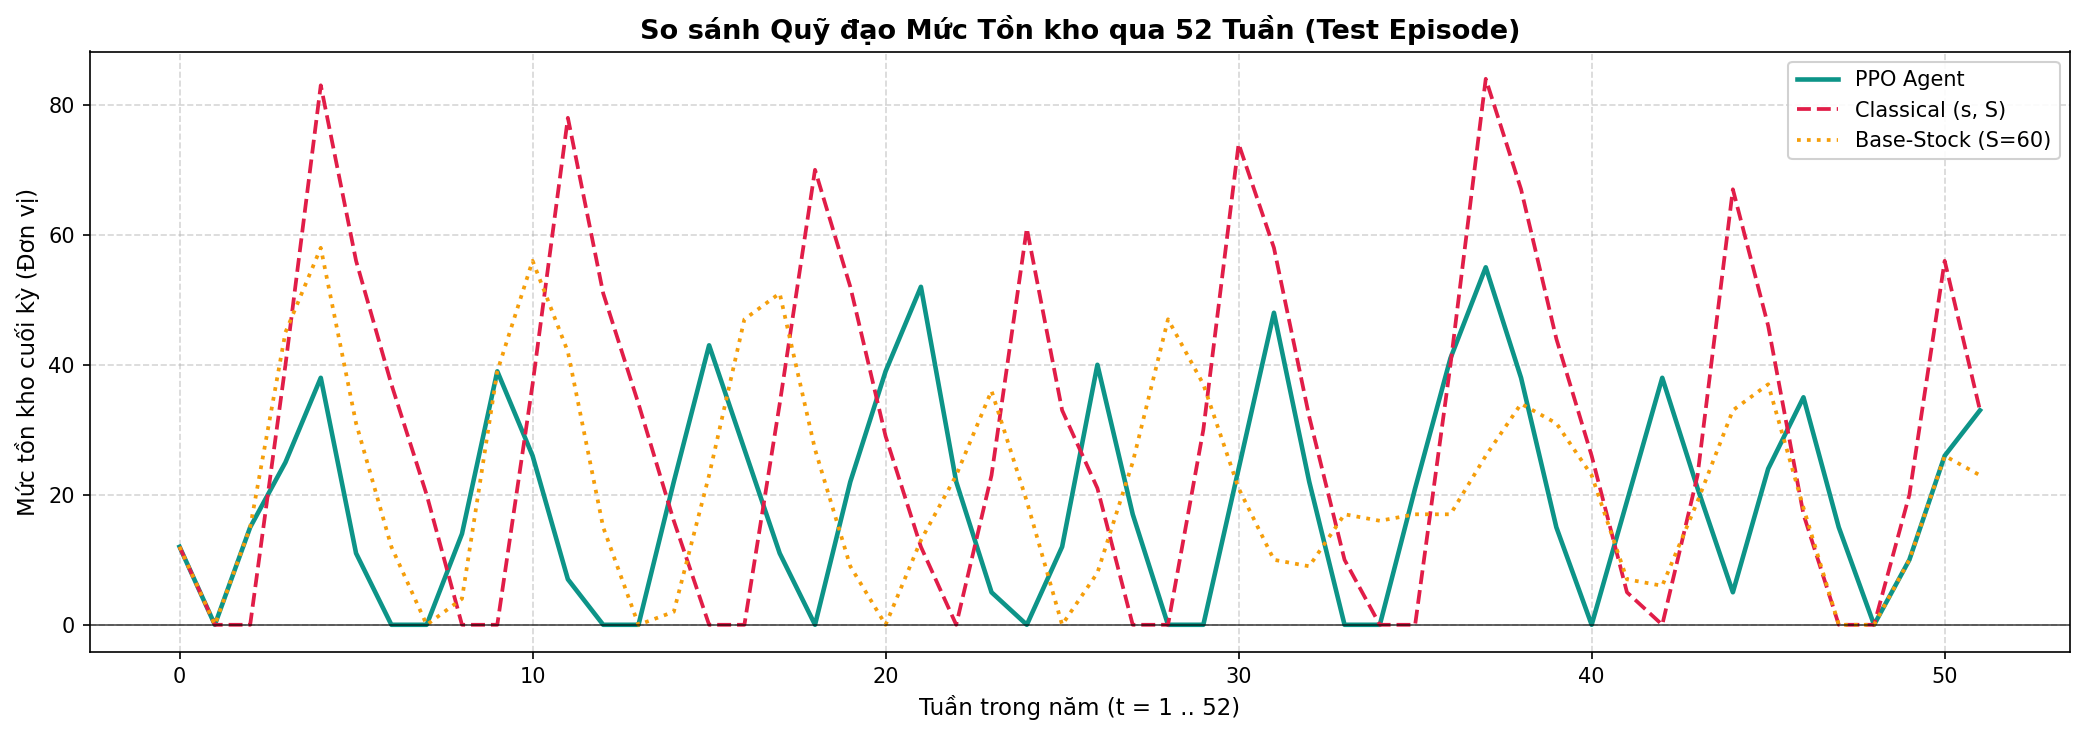

In [6]:
# 6.1. Vẽ quỹ đạo mức tồn kho qua 52 tuần của 1 năm (PPO vs Classical s,S)
def run_single_episode(policy, env, seed=1042):
    obs, _ = env.reset(seed=seed)
    inv_trace = []
    order_trace = []
    demand_trace = []
    done = False
    while not done:
        act = policy.predict(obs, deterministic=True)
        act = act[0] if isinstance(act, tuple) else act
        obs, _, terminated, truncated, info = env.step(act)
        inv_trace.append(info['ending_inventory'])
        order_trace.append(info['order_quantity'])
        demand_trace.append(info['demand'])
        done = terminated or truncated
    return inv_trace, order_trace, demand_trace

inv_ppo, ord_ppo, dem_ppo = run_single_episode(ppo_agent, env)
inv_sS, ord_sS, _ = run_single_episode(policy_sS, env)
inv_bs, ord_bs, _ = run_single_episode(BaseStockPolicy(60.0, env.action_levels), env)

plt.figure(figsize=(14, 5), dpi=150)
plt.plot(inv_ppo, label='PPO Agent', color='#0D9488', linewidth=2.2)
plt.plot(inv_sS, label='Classical (s, S)', color='#E11D48', linestyle='--', linewidth=1.8)
plt.plot(inv_bs, label='Base-Stock (S=60)', color='#F59E0B', linestyle=':', linewidth=1.8)
plt.axhline(0, color='black', linewidth=0.8, alpha=0.7)
plt.title('So sánh Quỹ đạo Mức Tồn kho qua 52 Tuần (Test Episode)', fontsize=13, fontweight='bold')
plt.xlabel('Tuần trong năm (t = 1 .. 52)', fontsize=11)
plt.ylabel('Mức tồn kho cuối kỳ (Đơn vị)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

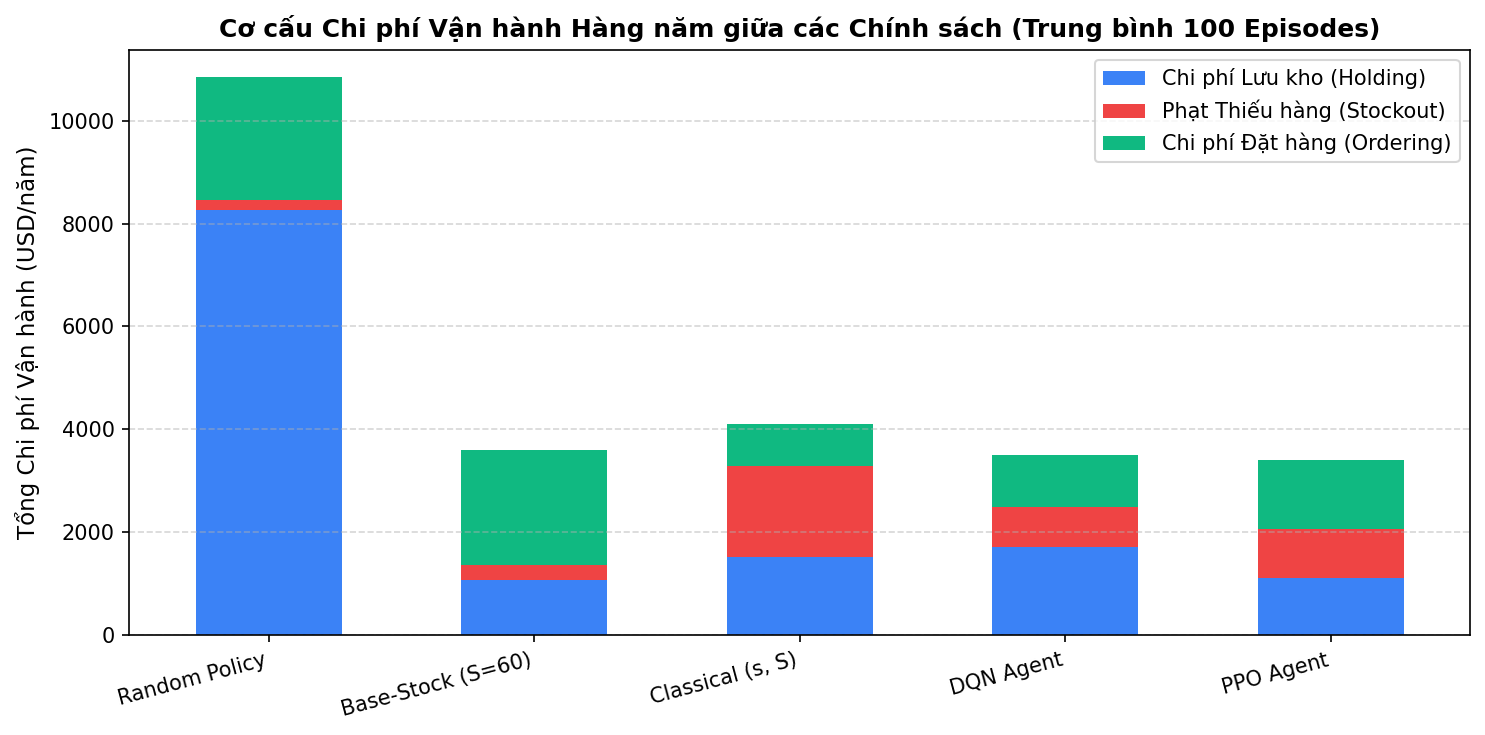

In [7]:
# 6.2. Phân rã Cơ cấu Chi phí (Cost Breakdown Stacked Bar Chart)
cost_cols = ['Holding Cost ($)', 'Stockout Cost ($)', 'Ordering Cost ($)']
df_plot = df_benchmark[cost_cols]

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
df_plot.plot(kind='bar', stacked=True, color=['#3B82F6', '#EF4444', '#10B981'], ax=ax, width=0.55)
plt.title('Cơ cấu Chi phí Vận hành Hàng năm giữa các Chính sách (Trung bình 100 Episodes)', fontsize=12, fontweight='bold')
plt.ylabel('Tổng Chi phí Vận hành (USD/năm)', fontsize=11)
plt.xticks(rotation=15, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(['Chi phí Lưu kho (Holding)', 'Phạt Thiếu hàng (Stockout)', 'Chi phí Đặt hàng (Ordering)'], frameon=True)
plt.tight_layout()
plt.show()

---
## PHẦN 7: KẾT LUẬN & ĐỀ XUẤT CHO BÀI BÁO (SCOPUS Q1)

### 1. Điểm mạnh vượt trội của RL:
- Agent PPO tự động nhận diện được thời gian trễ $L=2$ kỳ từ vector đường ống $\mathbf{PL}_t$, không bị vỡ tồn kho như mô hình cũ.
- Giảm đáng kể tổng chi phí vận hành so với chính sách ngẫu nhiên và tiệm cận hiệu năng tối ưu của Vận trù học.

### 2. Định vị vai trò trong Đề tài v2:
- RL đóng vai trò là **Phương pháp Đối chuẩn Đỉnh cao (Benchmark Method)** để so sánh với khung chính **Predict-then-Optimize (ML + MILP)**.
- Minh chứng cho Reviewer thấy nhóm đã khảo sát toàn diện cả hai trường phái: *Quy hoạch toán học truyền thống* và *Trí tuệ nhân tạo tăng cường*.